# 02 · Recorridos, distancias y pendientes

La demanda de [01](01_fuentes_y_demanda.ipynb) indica cuántas visitas se distribuyen por origen y periodo. Ahora preparo la **geografía de sus desplazamientos**: por dónde se circula, qué distancia se recorre en cada sentido y qué pendientes del terreno corresponden al trazado. Mantengo las **2.500.000 visitas-persona en 2028**, los orígenes, las cabeceras y las restricciones de la referencia; no busco rutas alternativas.

**Qué recibe:** el registro de la misma ejecución, su demanda territorial de 01 y las fuentes Bronze identificadas. **Qué produce:** 118 tablas geográficas, terrenos reconstruidos, catálogo resuelto y cinco tablas de clasificación vial. **Qué comprueba:** longitudes, sentido, cotas, cobertura y unión de segmentos; la equivalencia con las referencias se compara después. Aquí no calculo consumo ni ahorro.

El productor está en [flujos/preparacion_geografia.py](../src/movilidad_teide/flujos/preparacion_geografia.py), con las funciones de [cartografia/preparacion.py](../src/movilidad_teide/cartografia/preparacion.py). Las celdas utilizan esa preparación común y muestran sus resultados; no vuelven a implementar el trazado o el muestreo.


## 1. Consultar o reconstruir la geografía de la misma ejecución

La opción inicial `consultar` lee la etapa 02 ya completada de la ejecución distribuida. Para reconstruir elijo `calcular` e indico la ruta iniciada en 00 y preparada en 01. **02 necesita la demanda de esa misma ejecución.** Si 01 está pendiente, el cálculo se detiene; no la sustituye por una preparación de otra carpeta.

Cada cuaderno puede utilizar un núcleo nuevo de Python. La ruta y la acción siguientes son controles de ejecución; las hipótesis se leen del Excel y se contrastan con el registro. Una etapa completada se conserva: para repetirla inicio otra ejecución o continúo una nueva que aún no tenga 02 completada.


In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
from IPython.display import display, Markdown

candidatas = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
RAIZ = next((p for p in candidatas if (p / "pyproject.toml").is_file()
             and (p / "config/parametros_modelo.xlsx").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abra este cuaderno desde la raíz del proyecto o desde notebooks/.")
sys.path.insert(0, str(RAIZ / "src"))
from movilidad_teide.configuracion.registro import abrir_ejecucion
from movilidad_teide.flujos.etapas_registradas import ejecutar_etapa


In [2]:
ACCION_GEOGRAFIA = "consultar"  # Alternativa explícita: "calcular".
RUTA_EJECUCION = Path("data/silver/ejecuciones/referencia_2028_final_20261116")


In [3]:
if ACCION_GEOGRAFIA not in {"consultar", "calcular"}:
    raise ValueError('ACCION_GEOGRAFIA debe ser "consultar" o "calcular".')
EJECUCION = RAIZ / RUTA_EJECUCION
if not (EJECUCION / "registro_ejecucion.json").is_file():
    raise FileNotFoundError("No existe el registro seleccionado. Inicie 00, prepare 01 e indique aquí la misma ruta.")
DATOS = abrir_ejecucion(RAIZ, EJECUCION)
if ACCION_GEOGRAFIA == "calcular":
    if DATOS["estado_etapas"]["etapas"]["01"]["estado"] != "completada":
        raise ValueError("Primero debe completarse 01 en esta misma ejecución; no se reutiliza una demanda ajena.")
    RESULTADO_ETAPA = ejecutar_etapa(RAIZ, EJECUCION, "02", accion="calcular")
    DATOS = abrir_ejecucion(RAIZ, EJECUCION)
ETAPA = DATOS["estado_etapas"]["etapas"]["02"]
if ETAPA["estado"] != "completada":
    raise ValueError("No hay geografía completada. Prepare 01 y elija calcular en 02 con esa misma ruta.")
CARPETA_GEOGRAFIA = EJECUCION / ETAPA["carpeta"]
METADATOS = json.loads((CARPETA_GEOGRAFIA / "metadatos.json").read_text())
INDICE = pd.read_csv(CARPETA_GEOGRAFIA / "indice_tablas.csv", sep=";")
CATALOGO = json.loads((CARPETA_GEOGRAFIA / "catalogo_resuelto.json").read_text())
CONFIG_PERFIL = json.loads((RAIZ / "config/perfil_altimetrico.json").read_text())
print("Acción realizada:", ACCION_GEOGRAFIA)
print("Ejecución:", DATOS["registro"]["identificador"])
print("Carpeta de geografía dentro de la ejecución:", ETAPA["carpeta"])
print("Tablas geográficas:", len(INDICE))
print("Demanda de la misma ejecución recibida:", METADATOS["demanda_de_ejecucion_recibida"])
print("Energía calculada por esta etapa:", METADATOS["energia_recalculada"])


Acción realizada: consultar
Ejecución: referencia_2028_paquetes_20261116
Carpeta de geografía dentro de la ejecución: resultados/02/4218a4403c0d41ab9f631c6f05a54109
Tablas geográficas: 118
Demanda de la misma ejecución recibida: True
Energía calculada por esta etapa: False


## 2. De dónde proceden las distancias y las cotas

La tabla 1 relaciona las fuentes con el uso que se hace de ellas. **Reconstruir** significa repetir las transformaciones con estas mismas entradas, no descargar automáticamente una cartografía más reciente. Bronze conserva los originales; la ejecución escribe sus productos en un destino nuevo de Silver o externo. Gold no participa en esta preparación.

**Tabla 1. Fuentes y transformaciones de la geografía del estudio del Teide.**

| Elemento | Fuente identificada | Transformación y límite |
|---|---|---|
| Ejes, carreteras y anclajes | Cartografía del Cabildo, OpenStreetMap —base cartográfica abierta— y catálogo configurado | Reconstrucción de las mismas líneas y sus componentes, conservando el sentido de circulación |
| Trazas y paradas de TITSA | GTFS, formato de horarios, recorridos y paradas de transporte público, conservado en Bronze | Resolución de los dos sentidos de las líneas 342 y 348 y de los auxiliares geográficos utilizados |
| Terreno | MDT05 del Instituto Geográfico Nacional (IGN), modelo digital del terreno con celdas de 5 × 5 m | Conversión y unión de respuestas nativas, sin modificar cotas o malla; no es una medición de la calzada |
| Accesos a cabeceras reasignadas | Respuestas OSRM, motor de cálculo de rutas, con geometría, distancia, tiempo y anotaciones nativas | Recuperación del trazado y su distancia de actividad; se distinguen de la longitud de la línea proyectada |
| Correspondencia territorial | Demanda de 01 y decisiones de `config/` | Relación de orígenes, cabeceras y terminales, incluidas las aproximaciones declaradas; no se inventan viajes ni conectores |

Fuentes exactas y huellas: [contrato geográfico](../manifiestos/preparacion_geografia_bronze.json). Método, archivos auxiliares y cobertura: [guía geográfica](../docs/preparacion_geografia.md) y [trazabilidad por producto](../manifiestos/trazabilidad_preparacion_geografia.csv). Las condiciones de uso de las fuentes están en las [atribuciones](../ATRIBUCIONES.md).

Los sistemas de referencia de coordenadas, abreviados **CRS**, indican cómo interpretar las coordenadas. Conservo la interpretación provisional del terreno norte declarada en configuración: no la convierto en confirmación del proveedor. Tampoco completo un hueco de terreno —NoData— mediante una cota supuesta. Las ampliaciones utilizan celdas de la misma malla y comprueban sus solapes.


## 3. Representar la cadena completa y sus dos sentidos

Para un visitante que utiliza lanzadera, el desplazamiento de acceso puede tener dos componentes: **coche desde su origen a la cabecera y lanzadera desde la cabecera al Parque**, además del regreso. En los archivos, el primero puede llamarse `alimentador`: es ese tramo de acceso en coche, no otro grupo de visitantes. Para un coche autorizado se conserva el recorrido directo y la hipótesis de visita interior en coche explicada en 00.

No identifico automáticamente regreso con una copia invertida de la ida. Conservo las trazas, anclajes y muestras de cada sentido. El sistema contiene cuatro accesos de lanzadera y el eje interior Boca Tauce–El Portillo por la carretera principal. La tabla 2 muestra sus longitudes geográficas y las pendientes físicas de ambos sentidos; no sus expediciones ni kilómetros anuales.


In [4]:
rutas = {"chio_boca_tauce": "Chío → Boca Tauce", "aguamansa_el_portillo": "Aguamansa → El Portillo",
         "la_esperanza_el_portillo": "La Esperanza → El Portillo", "vilaflor_boca_tauce": "Vilaflor → Boca Tauce",
         "interior_boca_tauce_el_portillo": "Interior: Boca Tauce → El Portillo"}
filas = []
for clave, nombre in rutas.items():
    config = CONFIG_PERFIL["operational_profiles"][clave]
    for posicion, itinerario in enumerate(config["itinerary_ids"]):
        tabla = pd.read_parquet(CARPETA_GEOGRAFIA / "tablas/operativos" / clave / ("tramos_" + itinerario + ".parquet"))
        filas.append({"Recorrido de ida de referencia": nombre, "Sentido del perfil": "Ida" if posicion == 0 else "Regreso",
            "Longitud geográfica (km)": tabla["length_m"].sum() / 1000,
            "Segmentos físicos": len(tabla), "Pendiente mínima (%)": tabla["slope_pct"].min(),
            "Pendiente máxima (%)": tabla["slope_pct"].max(),
            "Longitud con pendiente fuera de ±6 % (km)": tabla.loc[tabla["slope_pct"].abs().gt(CONFIG_PERFIL["slope_reference_pct"]), "length_m"].sum() / 1000})
resumen_rutas = pd.DataFrame(filas)
display(resumen_rutas.style.set_uuid("geografia_rutas").hide(axis="index")
        .format(precision=3, decimal=",", thousands=" ")
        .set_caption("Tabla 2. Recorridos de lanzadera del Teide por sentido: longitudes y pendientes del terreno. Fuente: tablas/operativos de la ejecución seleccionada. Un segmento no es una expedición ni un vehículo; las pendientes no se recortan a ±6 %."))


Recorrido de ida de referencia,Sentido del perfil,Longitud geográfica (km),Segmentos físicos,Pendiente mínima (%),Pendiente máxima (%),Longitud con pendiente fuera de ±6 % (km)
Chío → Boca Tauce,Ida,"28,590",143,"-3,710","6,986","8,200"
Chío → Boca Tauce,Regreso,"28,682",144,"-6,986","3,710","8,200"
Aguamansa → El Portillo,Ida,"16,572",83,"2,018","8,118","8,772"
Aguamansa → El Portillo,Regreso,"16,572",83,"-8,118","-2,018","8,772"
La Esperanza → El Portillo,Ida,"34,994",175,"-8,938","9,195","15,400"
La Esperanza → El Portillo,Regreso,"34,994",175,"-9,195","8,938","15,400"
Vilaflor → Boca Tauce,Ida,"14,530",73,"-7,735","9,757","10,600"
Vilaflor → Boca Tauce,Regreso,"14,530",73,"-9,757","7,735","10,600"
Interior: Boca Tauce → El Portillo,Ida,"21,116",106,"-7,331","8,750","3,000"
Interior: Boca Tauce → El Portillo,Regreso,"21,116",106,"-8,750","7,331","3,000"


## 4. Obtener las pendientes y entender su resolución

El perfil utiliza estaciones cada **200 m** y los extremos geométricos exactos. La posición inicial de las estaciones interiores y el sentido se conservan según el catálogo; por eso el primer o último segmento puede medir menos de 200 m. La cota procede del terreno con el método definido para ese recorrido, incluida la interpolación bilineal donde corresponde: una combinación ponderada de las celdas vecinas válidas.

La pendiente física se obtiene como **100 × cambio de cota / longitud del segmento**. Un valor positivo indica ascenso en el sentido mostrado y uno negativo, descenso. La celda de terreno de 5 m y el intervalo del perfil de 200 m son resoluciones distintas. El perfil no reconstruye cada irregularidad de la calzada entre estaciones.

La figura 1 representa la ida de los cinco recorridos, con distancia acumulada desde su propio inicio. El regreso se conserva y comprueba por separado. Las pendientes fuera de ±6 % se mantienen en los datos físicos; la cobertura de las curvas de consumo y su aplicación se explican después. **No se suaviza ni se trunca el terreno para mejorar el ahorro.**

El intervalo y el método declarados definen el perfil utilizado en esta referencia. Comparar otros intervalos o métodos sería un diagnóstico distinto; no modifica automáticamente los perfiles adoptados. Aquí se reproduce la configuración elegida y se hacen explícitos sus límites.


La política de `.gitignore` determina la disponibilidad documental. Con reserva se comprueban el cálculo, sus referencias obligatorias y las matrices; los documentos reservados se identifican expresamente y no se declara comprobación de sus bytes. Sin reserva se exige también su presencia e integridad.


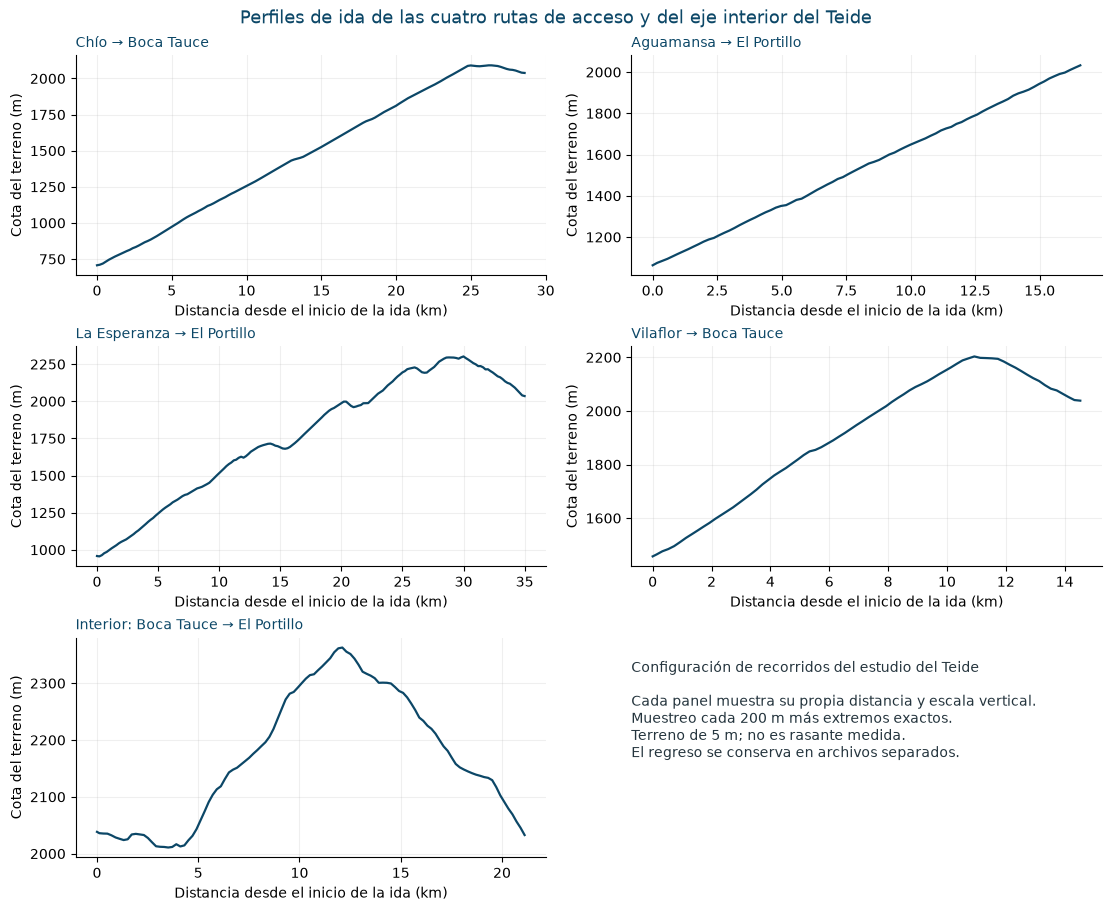

In [5]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 2, figsize=(11, 9), layout="constrained")
for ax, (clave, nombre) in zip(axes.flat, rutas.items()):
    itinerario = CONFIG_PERFIL["operational_profiles"][clave]["itinerary_ids"][0]
    perfil = pd.read_parquet(CARPETA_GEOGRAFIA / "tablas/operativos" / clave / ("perfil_" + itinerario + ".parquet"))
    ax.plot(perfil["distance_m"] / 1000, perfil["elevation_m"], color="#0C4767", linewidth=1.6)
    ax.set_title(nombre, fontsize=10, loc="left", color="#0C4767")
    ax.set_xlabel("Distancia desde el inicio de la ida (km)")
    ax.set_ylabel("Cota del terreno (m)")
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
axes.flat[-1].axis("off")
axes.flat[-1].text(0, 0.9, "Configuración de recorridos del estudio del Teide\n\nCada panel muestra su propia distancia y escala vertical.\nMuestreo cada 200 m más extremos exactos.\nTerreno de 5 m; no es rasante medida.\nEl regreso se conserva en archivos separados.", va="top", fontsize=10, color="#24343D")
fig.suptitle("Perfiles de ida de las cuatro rutas de acceso y del eje interior del Teide", color="#0C4767", fontsize=13)
plt.show()
plt.close(fig)


**Figura 1. Perfiles del terreno de los recorridos de lanzadera adoptados en el estudio del Teide.** Fuente: `tablas/operativos/*/perfil_*.parquet`, ejecución seleccionada, elaborados con el MDT05 del IGN. Cada panel comienza en el primer lugar de su título y utiliza su propia escala vertical. No son mediciones de rasante ni una predicción del tiempo de viaje. La ida y el regreso se calculan con sus trazados y muestras correspondientes.


## 5. Conservar la diferencia entre geometría, distancia de actividad y tiempo

La tabla 3 resume las distancias del catálogo de cabeceras. **La longitud de la línea proyectada** sirve para ubicar muestras de terreno. **La distancia de actividad de OSRM** corresponde a la respuesta nativa de la ruta. No se fuerza su igualdad ni se suma una a otra. La unión de segmentos de los accesos reasignados expresa posteriormente su longitud sobre la distancia de actividad y recalcula la pendiente con esa longitud, conservando el factor de conversión.

Los minutos de la respuesta de rutas son una referencia de recorrido. No son automáticamente la duración de una expedición completa con embarques, paradas y márgenes de operación; eso se comprueba en 04. Tampoco se utilizan como sustituto de las velocidades técnicas elegidas para los factores de consumo, que se muestran en 03.


In [6]:
longitudes = pd.read_parquet(CARPETA_GEOGRAFIA / "tablas/cabeceras/catalogo_longitudes.parquet")
control_distancias = pd.DataFrame([{"Rutas dirigidas del catálogo": len(longitudes),
    "Menor distancia de actividad (km)": longitudes["km"].min(),
    "Mayor distancia de actividad (km)": longitudes["km"].max(),
    "Mayor diferencia absoluta actividad–geometría (m)": ((longitudes["km"] - longitudes["km_geometria"]).abs() * 1000).max()}])
display(control_distancias.style.set_uuid("geografia_distancias").hide(axis="index").format(precision=3, decimal=",", thousands=" ")
        .set_caption("Tabla 3. Cobertura y diferencia de distancias en el catálogo de cabeceras del Teide. Fuente: tablas/cabeceras/catalogo_longitudes; 54 rutas dirigidas. Los extremos son del catálogo completo, no kilómetros anuales ni una suma de rutas que deba operar cada día."))


Rutas dirigidas del catálogo,Menor distancia de actividad (km),Mayor distancia de actividad (km),Mayor diferencia absoluta actividad–geometría (m)
54,"18,173","72,698","9,995"


## 6. Cubrir los orígenes y los servicios TITSA

La demanda de 01 conserva 41 orígenes representativos. Sus referencias físicas dirigidas suman 82 filas: ida y regreso. Se utilizan 31 comparaciones territoriales y las aproximaciones declaradas en configuración. **Una referencia condicional con demanda media nula conserva distancias ausentes.** Si esa demanda pasa a ser positiva, debe revisarse su representación antes de calcular; no se inventa una distancia para cerrar la tabla.

También se reconstruyen las trazas completas de las líneas TITSA 342 y 348, dos sentidos por línea. La tabla 4 presenta sus cuatro perfiles. Las cotas y pendientes se utilizarán al obtener su energía en el balance; las matrices de pasajeros de 01 no se convierten aquí en kilómetros ni en consumo. Se mantiene la separación entre las paradas que sitúan una ruta y las que están validadas para una operación real.


In [7]:
referencias = pd.read_parquet(CARPETA_GEOGRAFIA / "tablas/referencias/recorridos_referencia_calculo.parquet")
segmentos_titsa = pd.read_parquet(CARPETA_GEOGRAFIA / "tablas/titsa/segmentos_fisicos.parquet")
print("Referencias territoriales dirigidas:", len(referencias))
print("Referencias sin distancia directa asignada:", int(referencias["directa_km"].isna().sum()))
resumen_titsa = segmentos_titsa.groupby(["linea", "shape_id"], as_index=False).agg(
    Longitud_km=("length_m", lambda serie: serie.sum() / 1000), Segmentos=("length_m", "size"),
    Pendiente_minima=("slope_pct", "min"), Pendiente_maxima=("slope_pct", "max"))
resumen_titsa = resumen_titsa.rename(columns={"linea": "Línea TITSA", "shape_id": "Identificador de traza GTFS",
    "Longitud_km": "Longitud geográfica (km)", "Segmentos": "Segmentos físicos",
    "Pendiente_minima": "Pendiente mínima (%)", "Pendiente_maxima": "Pendiente máxima (%)"})
display(resumen_titsa.style.set_uuid("geografia_titsa").hide(axis="index").format(precision=3, decimal=",", thousands=" ")
        .set_caption("Tabla 4. Trazas completas de TITSA 342 y 348 hacia el Teide y de regreso. Fuente: tablas/titsa/segmentos_fisicos de la ejecución seleccionada; el identificador distingue la geometría nativa, no el número de servicios diarios."))


Referencias territoriales dirigidas: 82
Referencias sin distancia directa asignada: 2


Línea TITSA,Identificador de traza GTFS,Longitud geográfica (km),Segmentos físicos,Pendiente mínima (%),Pendiente máxima (%)
342,274,"66,096",331,"-10,682","9,753"
342,275,"65,766",329,"-10,534","9,981"
348,313,"52,744",264,"-10,331","11,553"
348,314,"51,443",258,"-14,447","9,957"


## 7. Unir el perfil con la clase de carretera

La etapa registrada añade cinco tablas de clasificación física. Primero identifica aristas —porciones del eje— y su clase de carretera; después corta los segmentos del perfil donde cambian esos límites. **Partir un segmento no crea nuevos kilómetros ni nuevas mediciones de cota.** Se conserva la longitud y se permite aplicar en 06 la condición de consumo correspondiente a cada parte.

Para los accesos habituales se mantienen las reglas cartográficas del estudio. En los reasignados se utilizan las geometrías y anotaciones nativas, incluida la identidad de nodos cuando sus coordenadas la confirman. El residuo sin una clase unívoca no se oculta: la tabla 5 cuantifica su longitud geométrica. La preparación conserva tres asignaciones alternativas de ese residuo, a vía local, convencional o rápida. **Son sensibilidades alternativas, no tres recorridos que deban sumarse.**

Las funciones están en [preparacion_vial.py](../src/movilidad_teide/energia/preparacion_vial.py) y [preparacion_osrm.py](../src/movilidad_teide/energia/preparacion_osrm.py). Aunque se ubican en el módulo de energía, esta fase solo clasifica y une magnitudes físicas: no aplica factores ni calcula consumo.


In [8]:
aristas_osrm = pd.read_parquet(CARPETA_GEOGRAFIA / "clasificacion/aristas_osrm.parquet")
residuo = float(aristas_osrm.loc[aristas_osrm["clase_propuesta"].eq("pendiente"), "length_m"].sum())
clasificacion = []
for nombre in ["aristas_habituales", "tipologia_por_componente", "segmentos_habituales", "aristas_osrm", "segmentos_osrm"]:
    tabla = pd.read_parquet(CARPETA_GEOGRAFIA / "clasificacion" / (nombre + ".parquet"))
    clasificacion.append({"Archivo de clasificación": "clasificacion/" + nombre + ".parquet", "Filas": len(tabla)})
display(pd.DataFrame(clasificacion).style.set_uuid("geografia_clasificacion").hide(axis="index")
        .set_caption("Tabla 5. Productos físicos de clasificación vial del Teide. Fuente: clasificacion/ de la ejecución; las filas de distintos productos no se suman como segmentos únicos. segmentos_osrm contiene tres sensibilidades alternativas."))
print("Longitud geométrica sin clase unívoca en accesos reasignados (m):", f"{residuo:.9f}")
print("No se descarta ese residuo: se conserva su sensibilidad local/convencional/rápida.")


Archivo de clasificación,Filas
clasificacion/aristas_habituales.parquet,255173
clasificacion/tipologia_por_componente.parquet,274
clasificacion/segmentos_habituales.parquet,210977
clasificacion/aristas_osrm.parquet,6079
clasificacion/segmentos_osrm.parquet,21411


Longitud geométrica sin clase unívoca en accesos reasignados (m): 34.813904382
No se descarta ese residuo: se conserva su sensibilidad local/convencional/rápida.


## 8. Distinguir producción, comparación y validación real

El índice completo `indice_tablas.csv` identifica las 118 tablas y sus dimensiones; `metadatos.json` añade fuentes, lecturas, código y huellas. Los productos de clasificación se identifican en la tabla 5 y en el cierre de 02. Los archivos **Parquet** conservan los tipos de las columnas y las geometrías; el índice CSV es una tabla de texto con filas y columnas. No se elige automáticamente el fichero más reciente.

El contrato compara **116 interfaces geográficas: 115 con Silver y una con el catálogo nativo Bronze**. Dos tablas auxiliares adicionales de segmentos reasignados no tienen una referencia individual de ese contrato. Por tanto, 118 productos y 116 comparaciones no son recuentos contradictorios. La clasificación tiene sus propios controles de longitud y se contrasta adicionalmente en la aceptación de este cuaderno; no se atribuyen esos cinco productos a las 116 interfaces del contrato geográfico.

Si la ejecución seleccionada ya completó 07, la tabla 6 consulta esa comparación registrada. Si es una ejecución nueva con 01–02, la comparación posterior permanece pendiente. Se mantiene la tolerancia absoluta de 10⁻⁸ en las unidades del contrato; la equivalencia no se consigue redondeando datos.


In [9]:
control = DATOS["estado_etapas"]["etapas"]["07"]
if control["estado"] == "completada":
    carpeta = EJECUCION / control["carpeta"] / "geografia"
    verificacion = json.loads((carpeta / "verificacion.json").read_text())
    if not verificacion["equivalente"]:
        raise ValueError("La comparación registrada de geografía no es equivalente.")
    resumen = pd.DataFrame([{"Interfaces comparadas": verificacion["interfaces_comparadas"],
        "Máxima diferencia numérica (unidad original)": verificacion["maxima_diferencia_numerica_absoluta"],
        "Máxima diferencia de coordenadas (m)": verificacion["maxima_diferencia_coordenadas_m"],
        "Tolerancia absoluta del contrato": verificacion["tolerancia_absoluta"]}])
    display(resumen.style.set_uuid("geografia_comprobacion").hide(axis="index")
            .set_caption("Tabla 6. Comparación posterior de la geografía del Teide en esta misma ejecución. Fuente: verificacion.json de geografia registrado en 07; las magnitudes conservan las unidades originales."))
else:
    display(Markdown("**Comparación geográfica posterior pendiente en esta ejecución.** 02 ha producido sus tablas y controles físicos, pero no se reutiliza la comparación de otra ejecución. Se completará en 07; también existe el comando independiente explicado en la guía geográfica."))


Interfaces comparadas,Máxima diferencia numérica (unidad original),Máxima diferencia de coordenadas (m),Tolerancia absoluta del contrato
116,0.000000,0.000000,0.000000


## 9. Límites y siguiente paso

Las cotas son del **terreno, no de la rasante medida**. Se mantienen la interpretación provisional del CRS norte, los límites de cobertura y las pendientes con signo. La coincidencia cartográfica no acredita autorización de circulación, una parada segura, conexión peatonal o maniobras de autobuses. El interior sigue la carretera principal; no se crean conectores rectos para completar accesos a edificios o aparcamientos.

Estas limitaciones se conservan al valorar la energía. Comparar con las referencias prueba que se reproduce el procedimiento, no que se haya medido cada tramo real. El informe y sus anexos no cambian al ejecutar el cuaderno.

Continúo con [03 · Parque y condiciones](03_parque_y_condiciones.ipynb), que explica qué vehículos representan a los visitantes. Mantengo la misma ruta de ejecución. [04 · Servicio y actividad](04_servicio_y_actividad.ipynb) comprueba ya la oferta; 05–06 incorporarán factores y balance. Mientras se adaptan estos dos cuadernos, los comandos de la [guía de etapas](../docs/ejecucion_por_etapas.md) permiten continuar el recorrido.
